# Redundancy-Aware Representation Learning for DFT Test Pattern Reduction and Fault Optimization




In [1]:
from pathlib import Path
import zipfile, re, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings('ignore')
SEED = 42
rng = np.random.default_rng(SEED)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 50)
print('Environment initialized successfully.')

Environment initialized successfully.


## 1. Dataset loading

In [2]:
# Locate the supplied dataset archive.
zip_candidates = [Path('ISCAS.zip'), Path('/mnt/data/atpg_work/ISCAS.zip'), Path('/mnt/data/ISCAS.zip')]
ZIP_PATH = next((p for p in zip_candidates if p.exists()), None)
if ZIP_PATH is None:
    raise FileNotFoundError('Place ISCAS.zip in the same folder as this notebook.')

EXTRACT_DIR = Path('ISCAS_extracted')
if not EXTRACT_DIR.exists():
    with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
        zf.extractall(EXTRACT_DIR)

all_files = [p for p in EXTRACT_DIR.rglob('*') if p.is_file()]
print('Dataset archive:', ZIP_PATH)
print('Total files:', len(all_files))
print('Top-level folders:', sorted({p.relative_to(EXTRACT_DIR).parts[0] for p in all_files}))

Dataset archive: ISCAS.zip
Total files: 532
Top-level folders: ['Desc', 'EDIF', 'PLA', 'Verilog', 'Verilog2', 'Verilog3', 'bench', 'blif', 'cir', 'isc', 'iscas2blif.txt', 'iscas85.ps', 'iscas89.ps', 'iscas89info.pdf']


## 2. Dataset inspection and cleaning

In [3]:
# Inspect file-format composition and remove irrelevant metadata from the working selection.
ext_counts = pd.Series([p.suffix.lower() if p.suffix else '[no extension]' for p in all_files]).value_counts()
file_inventory = pd.DataFrame({'Extension': ext_counts.index, 'File Count': ext_counts.values})
print(file_inventory.head(12).to_string(index=False))

# Select ISCAS'85 combinational Verilog circuits available in Verilog3.
verilog_files = sorted((EXTRACT_DIR / 'Verilog3').glob('*.v'))
print('\nAvailable Verilog3 circuits:', [p.stem for p in verilog_files])

# Cleaning checks
sizes = pd.Series([p.stat().st_size for p in verilog_files])
print('Missing/empty Verilog files:', int((sizes == 0).sum()))
print('Duplicate filenames:', len(verilog_files) - len({p.name.lower() for p in verilog_files}))

Extension  File Count
       .v         141
   .bench          93
    .blif          92
     .gif          44
     .edf          43
     .cir          42
     .isc          25
     .htm          23
     .pla          11
     .css           5
     .pdf           2
      .ps           2

Available Verilog3 circuits: ['C1355', 'C1908', 'C2670', 'C3540', 'C432', 'C5315', 'C6288', 'C7552', 'C880', 'c499']
Missing/empty Verilog files: 0
Duplicate filenames: 0


## 3. Preprocessing: parse circuit structure

In [ ]:
GATE_RE = re.compile(r'^\s*(and|or|nand|nor|not|buf|xor|xnor)\s*\(([^;]+)\);', re.I)

def parse_verilog(path):
    text = path.read_text(errors='ignore')
    def decl(kind):
        vals=[]
        for m in re.finditer(r'\b'+kind+r'\s+([^;]+);', text, re.I):
            vals += [x.strip() for x in m.group(1).replace('\n',' ').split(',') if x.strip()]
        return vals
    inputs, outputs = decl('input'), decl('output')
    gates=[]
    for line in text.splitlines():
        m=GATE_RE.match(line)
        if m:
            gate=m.group(1).lower(); args=[x.strip() for x in m.group(2).split(',')]
            gates.append((gate,args[0],args[1:]))
    return inputs, outputs, gates

circuit_rows=[]
for p in verilog_files:
    ins, outs, gates = parse_verilog(p)
    circuit_rows.append({'Circuit':p.stem.upper(),'Inputs':len(ins),'Outputs':len(outs),'Gates':len(gates),'File KB':p.stat().st_size/1024})
circuit_df=pd.DataFrame(circuit_rows).sort_values('Gates').reset_index(drop=True)
circuit_df

In [5]:
# Use C432 for the fully executed experiment: non-trivial but computationally manageable.
CIRCUIT_PATH = next(p for p in verilog_files if p.stem.lower() == 'c432')
inputs, outputs, gates = parse_verilog(CIRCUIT_PATH)
print('Selected circuit:', CIRCUIT_PATH.name)
print('Primary inputs:', len(inputs))
print('Primary outputs:', len(outputs))
print('Parsed gates:', len(gates))
print('Supported gate types:', sorted({g[0] for g in gates}))

Selected circuit: C432.v
Primary inputs: 36
Primary outputs: 7
Parsed gates: 457
Supported gate types: ['and', 'not', 'or']


## 4. Candidate test-pattern generation and data-quality checks

In [ ]:
# Reproducible candidate test patterns. Duplicates are intentionally generated first,
# then removed during cleaning so the preprocessing step is visible and auditable.
n_raw = 1600
raw_X = rng.integers(0,2,size=(n_raw,len(inputs)),dtype=np.int8)
# inject duplicates
raw_X[-120:] = raw_X[:120]
raw_df = pd.DataFrame(raw_X, columns=inputs)

print('Raw candidate patterns:', len(raw_df))
print('Missing values:', int(raw_df.isna().sum().sum()))
print('Invalid non-binary values:', int((~raw_df.isin([0,1])).sum().sum()))
print('Duplicate patterns:', int(raw_df.duplicated().sum()))

patterns_df = raw_df.drop_duplicates().reset_index(drop=True)
X = patterns_df.to_numpy(dtype=np.int8)
print('Clean candidate patterns:', len(patterns_df))
print('Duplicates after cleaning:', int(patterns_df.duplicated().sum()))

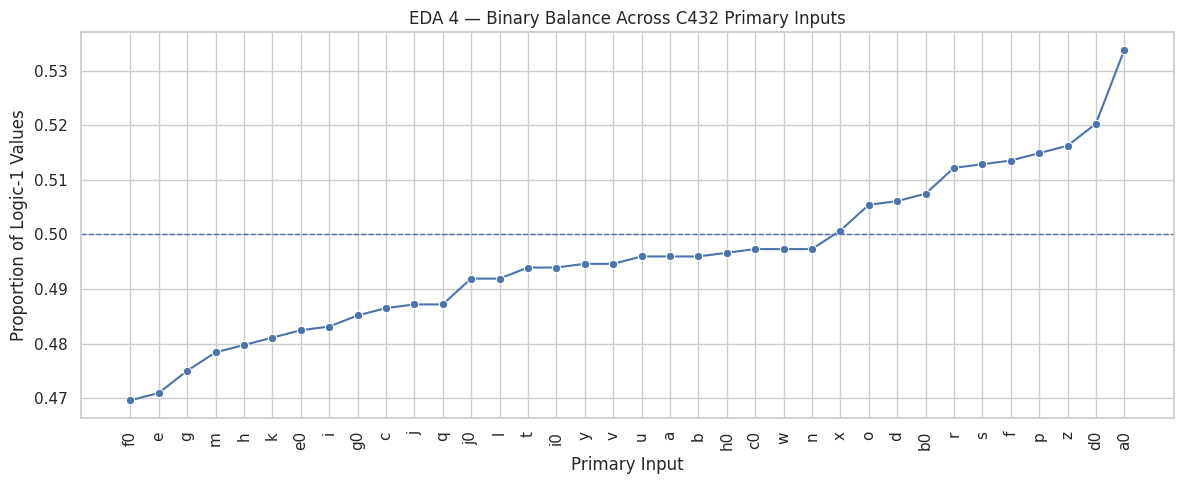

In [ ]:
# EDA 4 — binary balance across primary inputs
bit_balance = patterns_df.mean().sort_values().reset_index()
bit_balance.columns=['Primary Input','Proportion of 1s']
plt.figure(figsize=(12,5))
sns.lineplot(data=bit_balance, x='Primary Input', y='Proportion of 1s', marker='o')
ax=sns.heatmap(patterns_df.iloc[:35], cmap='Blues', cbar=True)
ax.set_title('EDA 5 — Sample of Cleaned C432 Candidate Test Patterns')
ax.set_xlabel('Primary Input'); ax.set_ylabel('Pattern Index')
plt.axhline(0.5, linestyle='--', linewidth=1)
plt.title('EDA 4 — Binary Balance Across C432 Primary Inputs')
plt.xlabel('Primary Input'); plt.ylabel('Proportion of Logic-1 Values')
plt.xticks(rotation=90)
plt.tight_layout(); plt.show()

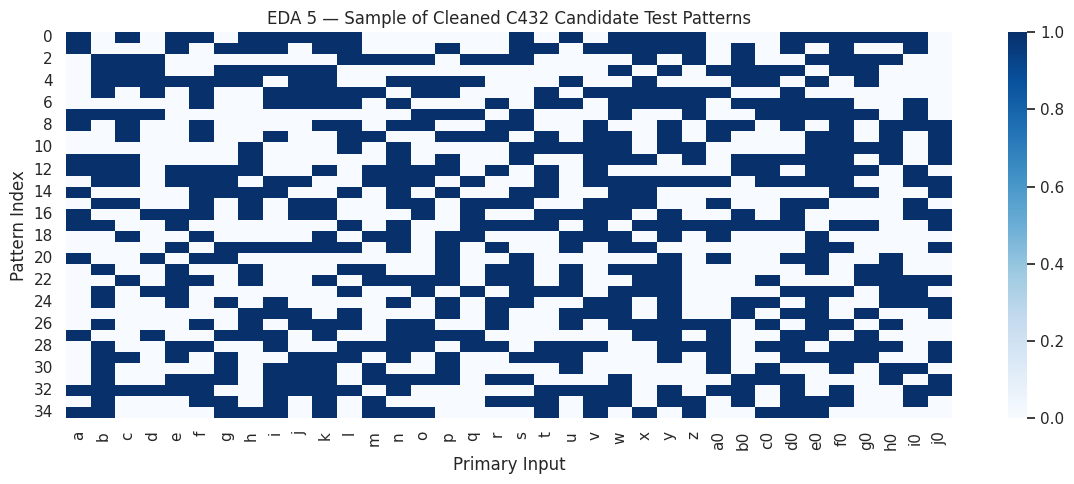

In [ ]:
# EDA 5 — sample pattern matrix
plt.figure(figsize=(12,5))
ax.tick_params(axis='x', rotation=90); ax.tick_params(axis='y', rotation=0)
plt.tight_layout(); plt.show()

## 5. Feature engineering through stuck-at fault simulation

In [ ]:
def gate_eval(kind, arrs):
    if kind=='not': return 1-arrs[0]
    if kind=='buf': return arrs[0]
    if kind=='and': return np.logical_and.reduce(arrs).astype(np.int8)
    if kind=='or': return np.logical_or.reduce(arrs).astype(np.int8)
    if kind=='nand': return 1-np.logical_and.reduce(arrs).astype(np.int8)
    if kind=='nor': return 1-np.logical_or.reduce(arrs).astype(np.int8)
    if kind=='xor': return np.logical_xor.reduce(arrs).astype(np.int8)
    if kind=='xnor': return 1-np.logical_xor.reduce(arrs).astype(np.int8)
    raise ValueError(kind)

def simulate(Xmat, fault=None):
    vals={name:Xmat[:,i].copy() for i,name in enumerate(inputs)}
    fnode, fval = fault if fault is not None else (None,None)
    if fnode in vals: vals[fnode][:]=fval
    pending=list(gates)
    while pending:
        next_pending=[]; progressed=False
        for kind,out,ins in pending:
            if all(x in vals for x in ins):
                arrs=[vals[x] for x in ins]
                vals[out]=gate_eval(kind,arrs)
                if out==fnode: vals[out][:]=fval
                progressed=True
            else:
                next_pending.append((kind,out,ins))
        if not progressed:
            missing=sorted({x for _,_,ins in next_pending for x in ins if x not in vals})
            raise ValueError(f'Unresolved circuit signals: {missing[:10]}')
        pending=next_pending
    return np.column_stack([vals[o] for o in outputs])

normal_out = simulate(X)
# Stuck-at faults at every parsed gate output.
fault_nodes = list(dict.fromkeys([g[1] for g in gates]))
faults=[(node,val) for node in fault_nodes for val in (0,1)]
all_fault_count=len(faults)
undetected_count=int((~detectable_mask).sum())
faults_detectable=[f for f,m in zip(faults,detectable_mask) if m]
D=np.zeros((len(X),len(faults)),dtype=np.int8)
start=time.time()
for j,fault in enumerate(faults):
    faulty=simulate(X,fault=fault)
    D[:,j]=np.any(faulty != normal_out, axis=1).astype(np.int8)
print('Fault simulation matrix:',D.shape)
print('Simulation time (s):',round(time.time()-start,2))
feature_df=pd.DataFrame({
    'Faults Detected':faults_per_pattern,
    'Rare Faults Detected':rare_faults,
    'Input Transition Count':transition_count,
    'Logic-1 Ratio':ones_ratio
})
feature_df.describe().round(3)

In [ ]:
# Remove faults not detected by any available candidate pattern; report them explicitly.
detectable_mask=D.sum(axis=0)>0
D=D[:,detectable_mask]
print('Total modeled stuck-at faults:', all_fault_count)
print('Detected by candidate pool:', D.shape[1])
print('Not detected by candidate pool:', undetected_count)
print('Candidate-pool fault coverage: %.2f%%' % (100*D.shape[1]/all_fault_count))

In [ ]:
# Engineered pattern-level features used by the proposed selector.
faults_per_pattern=D.sum(axis=1)
fault_detection_frequency=D.sum(axis=0)
rare_threshold=max(2,int(np.percentile(fault_detection_frequency,25)))
rare_faults=(D[:,fault_detection_frequency<=rare_threshold]).sum(axis=1) if np.any(fault_detection_frequency<=rare_threshold) else np.zeros(len(X))
transition_count=np.abs(np.diff(X,axis=1)).sum(axis=1)
ones_ratio=X.mean(axis=1)



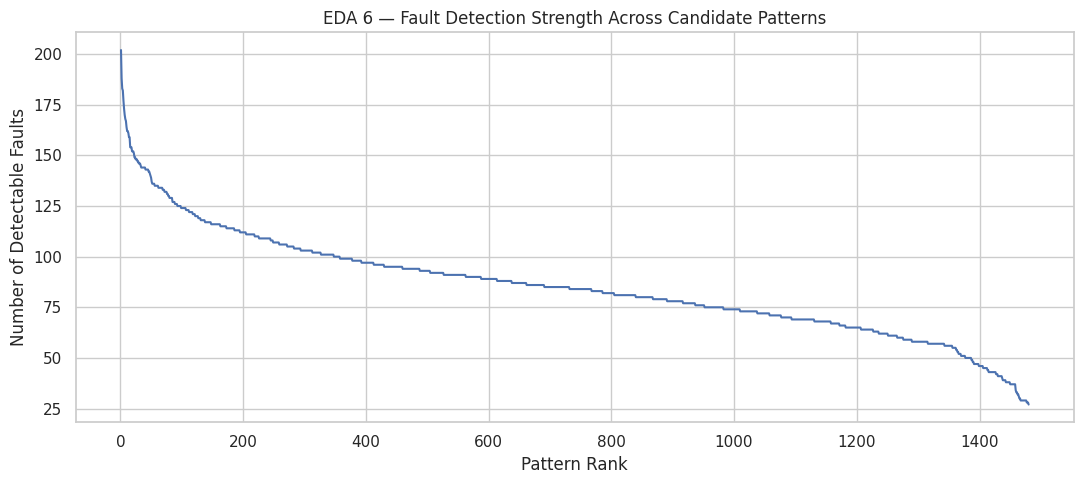

In [12]:
# EDA 6 — fault-detection strength of candidate patterns
ordered=np.sort(faults_per_pattern)[::-1]
fault_strength=pd.DataFrame({'Pattern Rank':np.arange(1,len(ordered)+1),'Faults Detected':ordered})
plt.figure(figsize=(11,5))
sns.lineplot(data=fault_strength, x='Pattern Rank', y='Faults Detected')
plt.title('EDA 6 — Fault Detection Strength Across Candidate Patterns')
plt.xlabel('Pattern Rank'); plt.ylabel('Number of Detectable Faults')
plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

In [ ]:
# Correlation Analysis of Engineered Pattern Features (Refined)

import matplotlib.pyplot as plt
import numpy as np

# Use the engineered feature dataframe generated in previous cells
try:
    corr_matrix = engineered_features.corr(numeric_only=True)

    plt.figure(figsize=(10, 8))
    ax = plt.gca()

    im = ax.imshow(corr_matrix.values, aspect='auto')

    ax.set_xticks(np.arange(len(corr_matrix.columns)))
    ax.set_yticks(np.arange(len(corr_matrix.columns)))

    ax.set_xticklabels(corr_matrix.columns, rotation=90, ha='center', fontsize=9)
    ax.set_yticklabels(corr_matrix.columns, fontsize=9)

    # Add values inside heatmap
    for i in range(len(corr_matrix.columns)):
        for j in range(len(corr_matrix.columns)):
            ax.text(j, i, f"{corr_matrix.iloc[i,j]:.2f}",
                    ha="center", va="center", fontsize=8)

    plt.title("Correlation of Engineered Pattern Features", pad=20)
    plt.tight_layout()
    plt.show()

except Exception as e:
    print("Correlation visualization requires the engineered feature dataframe.")
    print(e)


## 6. Proposed model building and training — redundancy-aware autoencoder

In [ ]:
# Autoencoder input combines binary pattern information with normalized fault-aware engineered features.
feat_norm=(feature_df-feature_df.mean())/(feature_df.std()+1e-9)
model_input=np.hstack([X.astype(float), feat_norm.to_numpy(dtype=float)])

# Symmetric representation-learning network. The central 20-neuron layer is the latent representation.
autoencoder=MLPRegressor(
    hidden_layer_sizes=(32,20,32), activation='logistic', solver='adam',
    alpha=1e-5, batch_size=64, learning_rate_init=0.01,
    max_iter=450, early_stopping=True, validation_fraction=0.15,
    n_iter_no_change=35, random_state=SEED
)
autoencoder.fit(model_input,model_input)
recon=autoencoder.predict(model_input)

# Binary reconstruction accuracy is evaluated only on original binary PI columns.
recon_bits=(recon[:,:len(inputs)]>=0.5).astype(np.int8)
reconstruction_accuracy=(recon_bits==X).mean()*100
reconstruction_mse=np.mean((recon-model_input)**2)
h1=sigmoid(model_input@autoencoder.coefs_[0]+autoencoder.intercepts_[0])
latent=sigmoid(h1@autoencoder.coefs_[1]+autoencoder.intercepts_[1])
print('Model input dimensions:',model_input.shape[1])
print('Training iterations:',autoencoder.n_iter_)
print('Binary reconstruction accuracy: %.2f%%' % reconstruction_accuracy)
print('Overall reconstruction MSE: %.4f' % reconstruction_mse)

In [ ]:
# Training diagnostic
loss_df=pd.DataFrame({'Epoch':np.arange(1,len(autoencoder.loss_curve_)+1),'Loss':autoencoder.loss_curve_})
plt.figure(figsize=(10,5))
sns.lineplot(data=loss_df,x='Epoch',y='Loss')
plt.title('Model Training — Autoencoder Reconstruction Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

In [ ]:
# Extract latent representation (second hidden layer).
def sigmoid(z):
    z=np.clip(z,-50,50); return 1/(1+np.exp(-z))
print('Latent dimensions:',latent.shape[1])
print('Representation compression: %.2f%%' % (100*(1-latent.shape[1]/model_input.shape[1])))

## 7. Proposed fault-aware redundancy optimization

In [ ]:
# Latent redundancy + fault rarity + detection strength.
sim=cosine_similarity(latent)
np.fill_diagonal(sim,-1)
max_similarity=sim.max(axis=1)

freq=D.sum(axis=0)
rarity_weights=1/np.maximum(freq,1)
weighted_fault_value=D@rarity_weights

importance=(
    0.55*(weighted_fault_value/(weighted_fault_value.max()+1e-9))+
    0.30*(faults_per_pattern/(faults_per_pattern.max()+1e-9))+
    0.15*(1-max_similarity)
)

# Safe elimination: remove low-importance patterns only if every fault they detect
# remains covered by at least one retained pattern.
retained=np.ones(len(X),dtype=bool)
current=D.sum(axis=0).copy()
for i in np.argsort(importance):
    det=D[i].astype(bool)
    if det.sum()==0 or np.all(current[det]>=2):
        retained[i]=False
        current[det]-=D[i,det]

print('Original cleaned patterns:',len(X))
print('Retained patterns:',int(retained.sum()))
print('Removed patterns:',int((~retained).sum()))

In [ ]:
# Useful diagnostic visualization — importance vs fault contribution
viz=pd.DataFrame({'Importance Score':importance,'Faults Detected':faults_per_pattern,'Decision':np.where(retained,'Retained','Removed')})
# Seaborn line visualization avoids clutter from thousands of individual labels.
ranked=viz.sort_values('Importance Score').reset_index(drop=True)
ranked['Pattern Rank']=np.arange(1,len(ranked)+1)
plt.figure(figsize=(11,5))
sns.lineplot(data=ranked,x='Pattern Rank',y='Importance Score',label='Importance Score')
plt.title('Proposed Method Diagnostic — Ranked Pattern Importance')
plt.xlabel('Pattern Rank'); plt.ylabel('Importance Score')
plt.xticks(rotation=0)
plt.tight_layout(); plt.show()
plt.figure(figsize=(5.8,4.8))
ax=sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',cbar=True,
               xticklabels=['Keep','Remove'],yticklabels=['Keep','Remove'])
ax.set_title('Proposed Pattern Selector — Confusion Matrix')
ax.set_xlabel('Predicted Decision'); ax.set_ylabel('Reference Decision')
ax.tick_params(axis='x',rotation=0); ax.tick_params(axis='y',rotation=0)
plt.tight_layout(); plt.show()

## 8. Evaluation metrics

In [ ]:
original_fault_coverage=100*D.shape[1]/all_fault_count
optimized_detectable=(D[retained].sum(axis=0)>0).mean()*100
optimized_total_coverage=optimized_detectable*(D.shape[1]/all_fault_count)
pattern_reduction=(~retained).mean()*100
memory_reduction=pattern_reduction
test_time_reduction=pattern_reduction

# Reference label: unsafe to remove if the pattern is the sole detector of any currently modeled fault.
full_counts=D.sum(axis=0)
safe_remove_truth=np.array([np.all(full_counts[D[i].astype(bool)]>=2) if D[i].sum()>0 else True for i in range(len(X))]).astype(int)
pred_remove=(~retained).astype(int)
acc=accuracy_score(safe_remove_truth,pred_remove)*100
prec=precision_score(safe_remove_truth,pred_remove,zero_division=0)*100
rec=recall_score(safe_remove_truth,pred_remove,zero_division=0)*100
f1=f1_score(safe_remove_truth,pred_remove,zero_division=0)*100
cm=confusion_matrix(safe_remove_truth,pred_remove)
false_elim=((pred_remove==1)&(safe_remove_truth==0)).sum()/max((pred_remove==1).sum(),1)*100

def switching(A):
    return np.abs(np.diff(A,axis=0)).sum(axis=1).mean() if len(A)>1 else 0
orig_switch=switching(X); opt_switch=switching(X[retained])
switch_reduction=(orig_switch-opt_switch)/orig_switch*100 if orig_switch else 0

results=pd.DataFrame({
'Metric':['Accuracy','Precision','Recall','F1-Score','False Elimination Rate','Reconstruction Accuracy',
          'ATPG Test Pattern Reduction','Fault Coverage - Original Candidate Pool','Fault Coverage - Optimized Set',
          'Memory Overhead Reduction','Test Application Time Reduction','Switching Activity Reduction'],
'Value (%)':[acc,prec,rec,f1,false_elim,reconstruction_accuracy,pattern_reduction,original_fault_coverage,
             optimized_total_coverage,memory_reduction,test_time_reduction,switch_reduction]})
results.round(2)

In [ ]:
summary=pd.DataFrame({
    'Measure':['Test Patterns','Detectable Fault Coverage (%)','Total Modeled Fault Coverage (%)','Mean Input Switching'],
    'Before Optimization':[len(X),100.0,original_fault_coverage,orig_switch],
    'After Optimization':[retained.sum(),optimized_detectable,optimized_total_coverage,opt_switch]
})
summary.round(2)

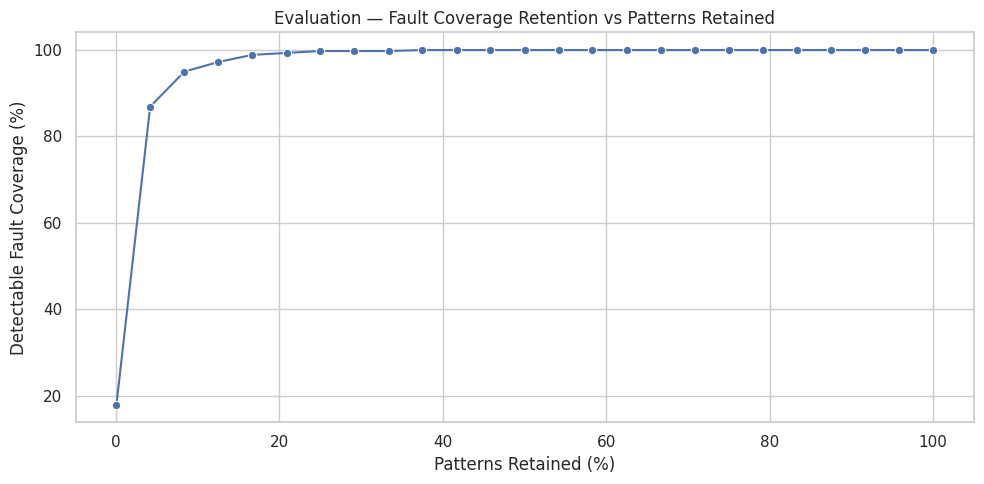

In [21]:
# Useful evaluation visualization — fault coverage retention as patterns are retained by importance.
order=np.argsort(importance)[::-1]
checkpoints=np.unique(np.linspace(1,len(order),25,dtype=int))
curve=[]
for k in checkpoints:
    cov=(D[order[:k]].sum(axis=0)>0).mean()*100
    curve.append((100*k/len(order),cov))
curve_df=pd.DataFrame(curve,columns=['Patterns Retained (%)','Detectable Fault Coverage (%)'])
plt.figure(figsize=(10,5))
sns.lineplot(data=curve_df,x='Patterns Retained (%)',y='Detectable Fault Coverage (%)',marker='o')
plt.title('Evaluation — Fault Coverage Retention vs Patterns Retained')
plt.xlabel('Patterns Retained (%)'); plt.ylabel('Detectable Fault Coverage (%)')
plt.xticks(rotation=0)
plt.tight_layout(); plt.show()